# Retail Customer Intelligence & Sales Prediction

An end-to-end Data Science project: **cleaning → EDA → RFM → K-Means segmentation → PCA → sales forecasting → business recommendations.**

**Business questions answered**
1. Who are the most valuable customers, and who is at risk of leaving?
2. Which products, categories and regions drive revenue?
3. How does revenue change over time, and is there seasonality?
4. Can customers be grouped by behaviour?
5. Can future sales be predicted, and what drives them?
6. What should the business *do* about it?

**How to use this notebook**
- Put your dataset at `data/retail_dataset.csv` (the UCI *Online Retail* dataset, Kaggle e-commerce datasets, etc. are auto-mapped to a standard schema).
- If no file is found, the notebook generates a realistic **synthetic Indian retail dataset** so everything runs end-to-end out of the box.

| Stage | Techniques |
|---|---|
| Preparation | validation audit, cleaning, feature engineering |
| Analytics | sales / product / category / region / customer EDA, Pareto analysis |
| Customer intelligence | RFM scoring + named segments, K-Means (elbow + silhouette), PCA |
| Prediction | leakage-free daily revenue forecasting (lags, rolling stats, time-based validation) |
| Action | auto-generated business insights + KPI dashboard |

## 1. Setup

In [1]:
import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score, calinski_harabasz_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- configuration -------------------------------------------------------
DATA_PATH  = Path("data/retail_dataset.csv")      # put your real dataset here
SYNTH_PATH = Path("data/synthetic_retail.csv")    # generated automatically if DATA_PATH is missing
IMG_DIR, OUT_DIR = Path("images"), Path("outputs")
K_OVERRIDE = None        # set e.g. 4 to force the number of clusters
FORECAST_DAYS = 30
for p in (DATA_PATH.parent, IMG_DIR, OUT_DIR):
    p.mkdir(exist_ok=True)

# ---- helpers ---------------------------------------------------------------
def inr(x):
    """Format a number as Indian rupees with lakh/crore shorthand."""
    a = abs(x)
    if a >= 1e7: return f"₹{x/1e7:,.2f} Cr"
    if a >= 1e5: return f"₹{x/1e5:,.2f} L"
    return f"₹{x:,.0f}"

def inr_axis(ax, axis="y"):
    def f(v, _):
        a = abs(v)
        if a >= 1e7: return f"₹{v/1e7:.1f}Cr"
        if a >= 1e5: return f"₹{v/1e5:.1f}L"
        if a >= 1e3: return f"₹{v/1e3:.0f}K"
        return f"₹{v:.0f}"
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mtick.FuncFormatter(f))

def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMG_DIR / name, dpi=150, bbox_inches="tight")

def title(text):
    display(Markdown(f"### {text}"))

## 2. Data Loading

The loader maps common column names (`InvoiceNo`, `StockCode`, `InvoiceDate`, `Country`, …) onto one standard schema:

`InvoiceNo, CustomerID, ProductID, ProductName, Category, Quantity, UnitPrice, Date, Region, Discount`

Missing optional columns (`Category`, `Region`, `Discount`) are derived or defaulted so the pipeline always runs.

In [2]:
def generate_synthetic_retail(seed=42, n_customers=1500, start="2024-01-01", end="2025-12-31"):
    """Realistic synthetic Indian retail data: seasonality (festive Q4), weekday effects,
    growth trend, behavioural customer types, discounts, plus deliberately dirty rows."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, end)
    month_boost = {1:.9, 2:.85, 3:.95, 4:.95, 5:1.0, 6:.9, 7:.9, 8:1.0, 9:1.05, 10:1.35, 11:1.5, 12:1.4}
    dow_boost = np.array([1.0, .95, .95, 1.0, 1.1, 1.3, 1.25])
    day_w = np.array([month_boost[d.month] * dow_boost[d.dayofweek] for d in dates]) * np.linspace(1, 1.25, len(dates))

    cats = {"Electronics": (2500, .6), "Fashion": (900, .5), "Home & Kitchen": (700, .5),
            "Beauty": (450, .4), "Grocery": (150, .35), "Sports": (1100, .5)}
    cat_pop = {"Grocery": .28, "Fashion": .22, "Home & Kitchen": .18, "Beauty": .12, "Electronics": .10, "Sports": .10}
    prods = []
    for c, (med, sig) in cats.items():
        for i in range(10):
            prods.append((f"{c[:3].upper()}-{i+1:03d}", f"{c} Item {i+1}", c,
                          round(float(rng.lognormal(np.log(med), sig)), 2), cat_pop[c] * rng.uniform(.5, 1.5)))
    prods = pd.DataFrame(prods, columns=["ProductID", "ProductName", "Category", "Price", "w"])
    prods["w"] /= prods["w"].sum()

    regions = ["Maharashtra", "Karnataka", "Delhi", "Tamil Nadu", "Telangana", "Gujarat",
               "West Bengal", "Odisha", "Uttar Pradesh"]
    r_p = np.array([.20, .15, .14, .13, .10, .09, .08, .04, .07]); r_p /= r_p.sum()

    # (share of customers, orders/month, spend multiplier, behaviour)
    types = {"champion": (.08, 2.2, 1.8), "loyal": (.20, 1.1, 1.2), "regular": (.37, .35, 1.0),
             "new": (.10, .9, 1.0), "lapsed": (.25, .5, 1.0)}
    names = list(types); shares = np.array([types[k][0] for k in names]); shares /= shares.sum()
    end_ts = pd.Timestamp(end)

    rows, inv = [], 100000
    for cid in range(10001, 10001 + n_customers):
        t = rng.choice(names, p=shares); _, rate, mult = types[t]
        a0, a1 = pd.Timestamp(start), end_ts
        if t == "new":    a0 = end_ts - pd.Timedelta(days=int(rng.integers(10, 70)))
        if t == "lapsed": a1 = end_ts - pd.Timedelta(days=int(rng.integers(150, 500)))
        if a1 <= a0: a1 = a0 + pd.Timedelta(days=30)
        mask = (dates >= a0) & (dates <= a1)
        window, w = dates[mask], day_w[mask]
        months = max((a1 - a0).days / 30, .5)
        n_orders = max(1, rng.poisson(rate * months))
        region = rng.choice(regions, p=r_p)
        for d in rng.choice(window, n_orders, p=w / w.sum()):
            inv += 1
            disc = rng.choice([0, .05, .10, .15, .20], p=[.55, .15, .15, .10, .05] if pd.Timestamp(d).month != 11
                              else [.30, .15, .25, .20, .10])
            for j in rng.choice(len(prods), min(1 + rng.poisson(1.5), 6), replace=False, p=prods["w"]):
                p = prods.iloc[j]
                rows.append((f"INV{inv}", cid, p.ProductID, p.ProductName, p.Category,
                             1 + rng.poisson(.8 * mult), round(p.Price * rng.uniform(.97, 1.03), 2),
                             pd.Timestamp(d), region, disc))
    df = pd.DataFrame(rows, columns=["InvoiceNo", "CustomerID", "ProductID", "ProductName", "Category",
                                     "Quantity", "UnitPrice", "Date", "Region", "Discount"])
    # inject realistic dirt so the cleaning stage has real work to do
    n = len(df)
    df["CustomerID"] = df["CustomerID"].astype(float)
    df.loc[rng.choice(n, int(.010 * n), replace=False), "CustomerID"] = np.nan
    df.loc[rng.choice(n, int(.005 * n), replace=False), "Quantity"] *= -1
    df.loc[rng.choice(n, int(.002 * n), replace=False), "UnitPrice"] = 0
    df = pd.concat([df, df.sample(int(.005 * n), random_state=seed)], ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


ALIASES = {
    "InvoiceNo":   ["invoiceno", "invoice", "transactionid", "orderid", "invoiceid"],
    "CustomerID":  ["customerid", "custid", "customer", "userid"],
    "ProductID":   ["productid", "stockcode", "sku", "itemid"],
    "ProductName": ["productname", "description", "product", "itemname"],
    "Category":    ["category", "productcategory"],
    "Quantity":    ["quantity", "qty"],
    "UnitPrice":   ["unitprice", "price"],
    "Date":        ["date", "invoicedate", "transactiondate", "orderdate"],
    "Region":      ["region", "country", "state", "city"],
    "Discount":    ["discount"],
}
KEYWORD_CATEGORIES = {   # used only when the dataset has no category column (e.g. UCI Online Retail)
    "Bags & Storage": ["bag", "box", "tin", "basket", "jar", "case"],
    "Lighting & Candles": ["light", "lantern", "candle", "lamp"],
    "Cards & Wrap": ["card", "wrap", "paper", "ribbon", "sticker"],
    "Kitchen & Dining": ["mug", "cup", "tea", "plate", "bowl", "cake", "spoon", "glass"],
    "Decor & Gifts": ["heart", "frame", "clock", "sign", "decor", "cushion", "doormat"],
}

def standardize(df):
    norm = {c: re.sub(r"[^a-z0-9]", "", c.lower()) for c in df.columns}
    rename = {}
    for canon, opts in ALIASES.items():
        for c, n in norm.items():
            if n in opts and canon not in rename.values():
                rename[c] = canon; break
    df = df.rename(columns=rename)
    missing_core = [c for c in ["InvoiceNo", "CustomerID", "Quantity", "UnitPrice", "Date"] if c not in df]
    assert not missing_core, f"Dataset is missing required columns: {missing_core}"
    if "ProductID" not in df:   df["ProductID"] = df.get("ProductName", "UNKNOWN")
    if "ProductName" not in df: df["ProductName"] = df["ProductID"].astype(str)
    if "Region" not in df:      df["Region"] = "Unknown"
    if "Discount" not in df:    df["Discount"] = 0.0
    if "Category" not in df:
        def cat(s):
            s = str(s).lower()
            return next((k for k, v in KEYWORD_CATEGORIES.items() if any(w in s for w in v)), "Other")
        df["Category"] = df["ProductName"].map(cat)
    if df["Discount"].max() > 1: df["Discount"] = df["Discount"] / 100   # percent -> fraction
    return df[list(ALIASES)]


if DATA_PATH.exists():
    try:    raw = pd.read_csv(DATA_PATH)
    except UnicodeDecodeError: raw = pd.read_csv(DATA_PATH, encoding="latin-1")
    SOURCE = f"Real dataset: {DATA_PATH}"
else:
    raw = generate_synthetic_retail(SEED)
    raw.to_csv(SYNTH_PATH, index=False)
    SOURCE = f"Synthetic dataset (saved to {SYNTH_PATH}) - drop your own CSV at {DATA_PATH} to use real data"

df = standardize(raw)
print(SOURCE)
display(df.head())

Synthetic dataset (saved to data/synthetic_retail.csv) - drop your own CSV at data/retail_dataset.csv to use real data


,InvoiceNo,CustomerID,ProductID,ProductName,Category,Quantity,UnitPrice,Date,Region,Discount
0,INV118330,11274.0,HOM-006,Home & Kitchen Item 6,Home & Kitchen,2,962.16,2024-04-02,Delhi,0.10
1,INV101272,10095.0,HOM-003,Home & Kitchen Item 3,Home & Kitchen,1,491.45,2024-05-23,Gujarat,0.15
2,INV113673,10958.0,HOM-004,Home & Kitchen Item 4,Home & Kitchen,3,763.83,2024-10-17,Maharashtra,0.20
3,INV108345,10583.0,FAS-009,Fashion Item 9,Fashion,1,859.51,2025-07-25,Gujarat,0.00
4,INV101583,10114.0,SPO-008,Sports Item 8,Sports,3,817.76,2025-10-29,Gujarat,0.10


In [3]:
print(f"Records: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.info()
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("\nNumerical :", num_cols)
print("Categorical:", cat_cols)
display(df.describe().T.round(2))

Records: 54,063   Columns: 10
<class 'pandas.DataFrame'>
RangeIndex: 54063 entries, 0 to 54062
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    54063 non-null  str           
 1   CustomerID   53524 non-null  float64       
 2   ProductID    54063 non-null  str           
 3   ProductName  54063 non-null  str           
 4   Category     54063 non-null  str           
 5   Quantity     54063 non-null  int64         
 6   UnitPrice    54063 non-null  float64       
 7   Date         54063 non-null  datetime64[us]
 8   Region       54063 non-null  str           
 9   Discount     54063 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(5)
memory usage: 4.1 MB

Numerical : ['CustomerID', 'Quantity', 'UnitPrice', 'Discount']
Categorical: ['InvoiceNo', 'ProductID', 'ProductName', 'Category', 'Date', 'Region']


,count,mean,min,25%,50%,75%,max,std
CustomerID,53524.0,10751.292878,10001.0,10375.0,10735.0,11145.0,11500.0,434.513825
Quantity,54063.0,2.02264,-7.0,1.0,2.0,3.0,9.0,1.095968
UnitPrice,54063.0,923.648863,0.0,190.29,643.15,1108.965,4364.27,977.127962
Date,54063,2025-01-15 18:33:12.475445,2024-01-01 00:00:00,2024-07-27 00:00:00,2024-12-28 00:00:00,2025-07-26 00:00:00,2025-12-31 00:00:00,NaN
Discount,54063.0,0.051234,0.0,0.0,0.0,0.1,0.2,0.064154


## 3. Data Cleaning & Validation

An **audit table** quantifies each data-quality issue *before* anything is removed, so every cleaning decision is traceable.

| Issue | Decision |
|---|---|
| Missing customer ID | drop (customer-level analysis impossible) |
| Quantity ≤ 0 | drop (returns / cancellations - not sales) |
| Unit price ≤ 0 | drop (free samples / data errors) |
| Invalid dates | drop |
| Exact duplicates | drop |
| Discount outside 0–90 % | clip |

In [4]:
clean = df.copy()
clean["Date"] = pd.to_datetime(clean["Date"], errors="coerce")

audit = pd.Series({
    "Raw rows": len(clean),
    "Missing values (any column)": int(clean.isnull().any(axis=1).sum()),
    "Missing CustomerID": int(clean["CustomerID"].isnull().sum()),
    "Invalid / missing dates": int(clean["Date"].isnull().sum()),
    "Quantity <= 0 (returns/cancellations)": int((clean["Quantity"] <= 0).sum()),
    "UnitPrice <= 0": int((clean["UnitPrice"] <= 0).sum()),
    "Exact duplicate rows": int(clean.duplicated().sum()),
    "Discount outside [0, 0.9]": int((~clean["Discount"].between(0, .9)).sum()),
}, name="rows affected")
display(audit.to_frame())

clean = clean.drop_duplicates()
clean = clean.dropna(subset=["CustomerID", "Date", "InvoiceNo", "Quantity", "UnitPrice"])
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]
clean["Discount"] = clean["Discount"].fillna(0).clip(0, .9)
clean["Category"] = clean["Category"].fillna("Uncategorized")
clean["Region"] = clean["Region"].fillna("Unknown")
clean["CustomerID"] = clean["CustomerID"].astype(int)
clean = clean.reset_index(drop=True)

print(f"Rows kept: {len(clean):,} of {len(df):,}  ({len(clean)/len(df):.1%})")
print(f"Date range: {clean['Date'].min().date()} -> {clean['Date'].max().date()}")

,rows affected
Raw rows,54063
Missing values (any column),539
Missing CustomerID,539
Invalid / missing dates,0
Quantity <= 0 (returns/cancellations),268
UnitPrice <= 0,108
Exact duplicate rows,268
"Discount outside [0, 0.9]",0


Rows kept: 52,887 of 54,063  (97.8%)
Date range: 2024-01-01 -> 2025-12-31


## 4. Feature Engineering

In [5]:
clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"] * (1 - clean["Discount"])   # net revenue
clean["Year"]       = clean["Date"].dt.year
clean["Quarter"]    = clean["Date"].dt.quarter
clean["Month"]      = clean["Date"].dt.month
clean["Day"]        = clean["Date"].dt.day
clean["DayOfWeek"]  = clean["Date"].dt.dayofweek
clean["DayName"]    = clean["Date"].dt.day_name()
clean["WeekOfYear"] = clean["Date"].dt.isocalendar().week.astype(int)
clean["IsWeekend"]  = (clean["DayOfWeek"] >= 5).astype(int)
clean["YearMonth"]  = clean["Date"].dt.to_period("M")
display(clean.head())

,InvoiceNo,CustomerID,ProductID,ProductName,Category,Quantity,UnitPrice,Date,Region,Discount,Revenue,Year,Quarter,Month,Day,DayOfWeek,DayName,WeekOfYear,IsWeekend,YearMonth
0,INV118330,11274,HOM-006,Home & Kitchen Item 6,Home & Kitchen,2,962.16,2024-04-02,Delhi,0.10,1731.8880,2024,2,4,2,1,Tuesday,14,0,2024-04
1,INV101272,10095,HOM-003,Home & Kitchen Item 3,Home & Kitchen,1,491.45,2024-05-23,Gujarat,0.15,417.7325,2024,2,5,23,3,Thursday,21,0,2024-05
2,INV113673,10958,HOM-004,Home & Kitchen Item 4,Home & Kitchen,3,763.83,2024-10-17,Maharashtra,0.20,1833.1920,2024,4,10,17,3,Thursday,42,0,2024-10
3,INV108345,10583,FAS-009,Fashion Item 9,Fashion,1,859.51,2025-07-25,Gujarat,0.00,859.5100,2025,3,7,25,4,Friday,30,0,2025-07
4,INV101583,10114,SPO-008,Sports Item 8,Sports,3,817.76,2025-10-29,Gujarat,0.10,2207.9520,2025,4,10,29,2,Wednesday,44,0,2025-10


## 5. Exploratory Data Analysis

### 5.1 Headline sales metrics

In [6]:
order_values = clean.groupby("InvoiceNo")["Revenue"].sum()
kpis = {
    "Total revenue": inr(clean["Revenue"].sum()),
    "Total transactions (orders)": f"{clean['InvoiceNo'].nunique():,}",
    "Total customers": f"{clean['CustomerID'].nunique():,}",
    "Total units sold": f"{clean['Quantity'].sum():,}",
    "Average order value": inr(order_values.mean()),
    "Median order value": inr(order_values.median()),
    "Average discount given": f"{clean['Discount'].mean():.1%}",
}
display(pd.Series(kpis, name="value").to_frame())

,value
Total revenue,₹9.45 Cr
Total transactions (orders),"21,489"
Total customers,"1,500"
Total units sold,"108,113"
Average order value,"₹4,396"
Median order value,"₹3,103"
Average discount given,5.1%


### 5.2 Monthly sales trend & seasonality

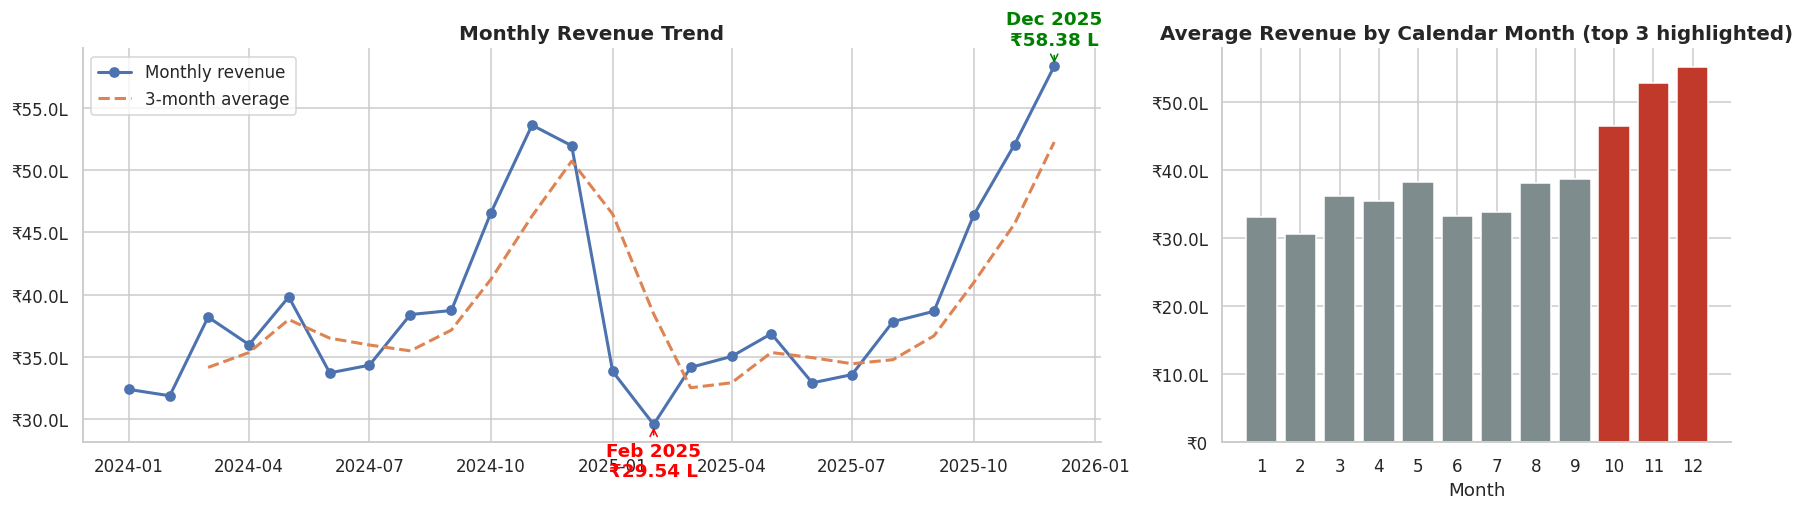

Highest month: Dec 2025 (₹58.38 L)   Lowest month: Feb 2025 (₹29.54 L)
Average MoM growth: 3.5%   First->last month change: +80.4%
Note: the first / last calendar month may be partial in real datasets.


In [7]:
monthly = clean.groupby("YearMonth")["Revenue"].sum()
monthly.index = monthly.index.to_timestamp()
mom = monthly.pct_change() * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(monthly.index, monthly.values, marker="o", lw=2, label="Monthly revenue")
ax[0].plot(monthly.index, monthly.rolling(3).mean(), ls="--", lw=2, label="3-month average")
hi, lo = monthly.idxmax(), monthly.idxmin()
for d, c in ((hi, "green"), (lo, "red")):
    ax[0].annotate(f"{d:%b %Y}\n{inr(monthly[d])}", (d, monthly[d]), textcoords="offset points",
                   xytext=(0, 14 if d == hi else -34), ha="center", color=c, fontweight="bold",
                   arrowprops=dict(arrowstyle="->", color=c))
ax[0].set_title("Monthly Revenue Trend"); ax[0].legend(); inr_axis(ax[0])

seasonal = clean.groupby(["Year", "Month"])["Revenue"].sum().groupby("Month").mean()
colors = ["#c0392b" if m in seasonal.nlargest(3).index else "#7f8c8d" for m in seasonal.index]
ax[1].bar(seasonal.index, seasonal.values, color=colors)
ax[1].set_xticks(range(1, 13)); ax[1].set_title("Average Revenue by Calendar Month (top 3 highlighted)")
inr_axis(ax[1]); ax[1].set_xlabel("Month")
save_fig("sales_trend.png"); plt.show()

print(f"Highest month: {hi:%b %Y} ({inr(monthly[hi])})   Lowest month: {lo:%b %Y} ({inr(monthly[lo])})")
print(f"Average MoM growth: {mom.mean():.1f}%   First->last month change: {monthly.iloc[-1]/monthly.iloc[0]-1:+.1%}")
print("Note: the first / last calendar month may be partial in real datasets.")

### 5.3 Day-of-week behaviour

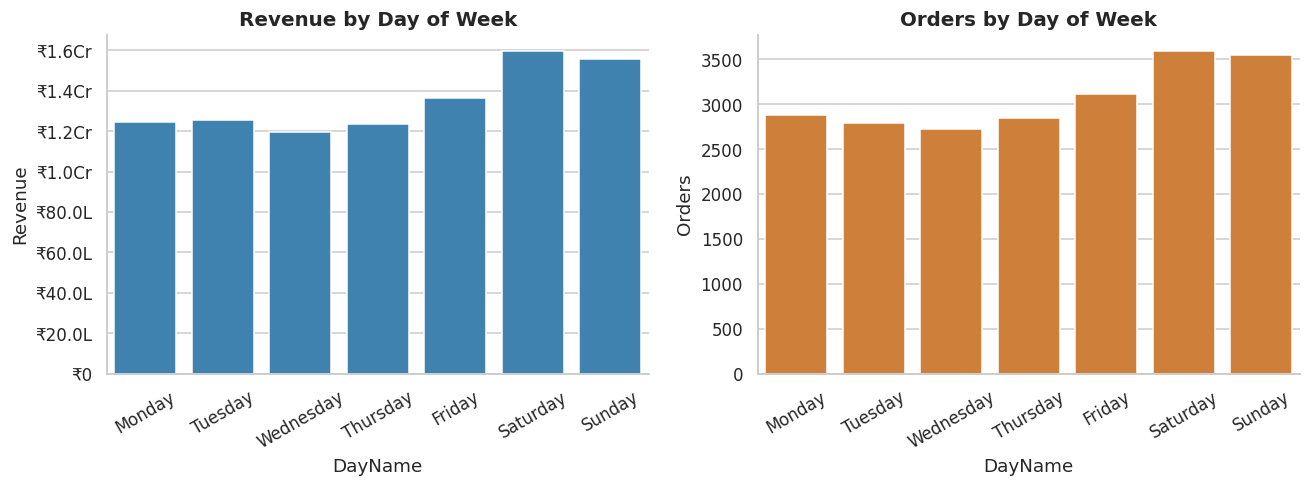

In [8]:
order_dow = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = clean.groupby("DayName").agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique")).reindex(order_dow)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=dow.index, y=dow["Revenue"], ax=ax[0], color="#2e86c1"); inr_axis(ax[0])
ax[0].set_title("Revenue by Day of Week"); ax[0].tick_params(axis="x", rotation=30)
sns.barplot(x=dow.index, y=dow["Orders"], ax=ax[1], color="#e67e22")
ax[1].set_title("Orders by Day of Week"); ax[1].tick_params(axis="x", rotation=30)
plt.show()

### 5.4 Product analysis

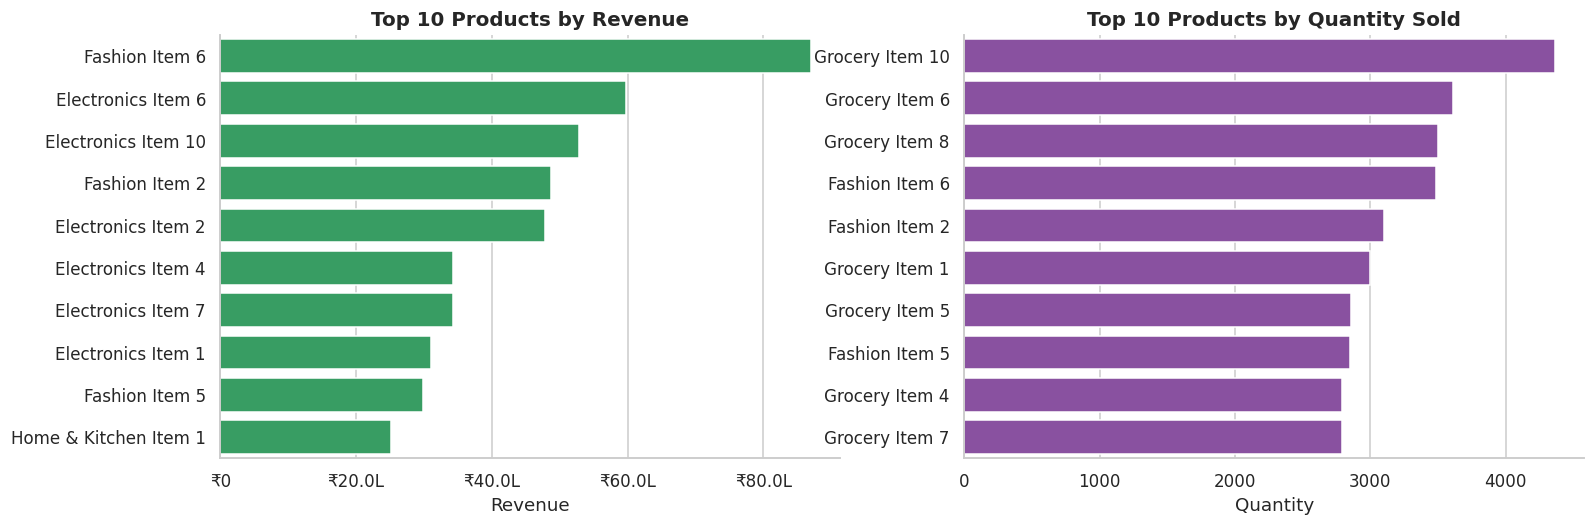

30 of 60 products (50%) generate 80% of revenue.


In [9]:
prod = (clean.groupby(["ProductID", "ProductName"])
              .agg(Revenue=("Revenue", "sum"), Quantity=("Quantity", "sum"), Orders=("InvoiceNo", "nunique"))
              .reset_index())
prod["Label"] = prod["ProductName"].str.slice(0, 32)
top_rev = prod.nlargest(10, "Revenue"); top_qty = prod.nlargest(10, "Quantity")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=top_rev, y="Label", x="Revenue", ax=ax[0], color="#27ae60"); inr_axis(ax[0], "x")
ax[0].set_title("Top 10 Products by Revenue"); ax[0].set_ylabel("")
sns.barplot(data=top_qty, y="Label", x="Quantity", ax=ax[1], color="#8e44ad")
ax[1].set_title("Top 10 Products by Quantity Sold"); ax[1].set_ylabel("")
plt.show()

prod_sorted = prod.sort_values("Revenue", ascending=False)
share = prod_sorted["Revenue"].cumsum() / prod_sorted["Revenue"].sum()
n80 = int((share < .8).sum() + 1)
print(f"{n80} of {len(prod)} products ({n80/len(prod):.0%}) generate 80% of revenue.")

### 5.5 Category analysis

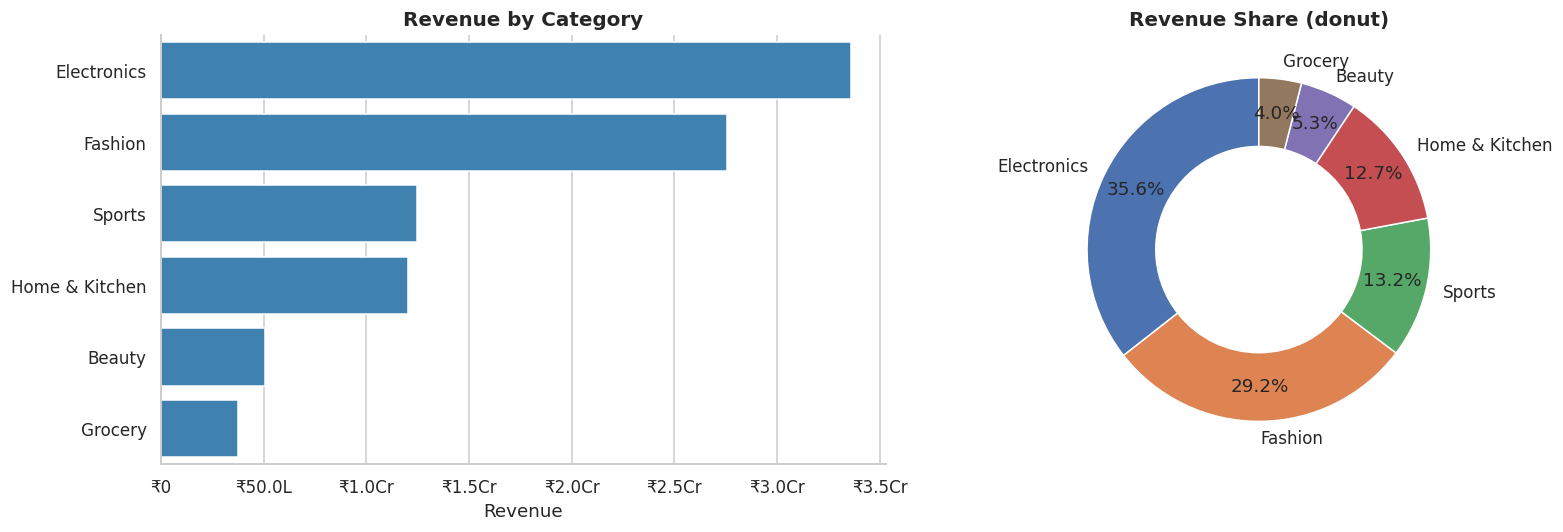

,Revenue,Quantity,Orders,AvgDiscount,Share
Category,,,,,
Electronics,₹3.36 Cr,11791,5289,5.1%,35.6%
Fashion,₹2.75 Cr,23384,9351,5.1%,29.2%
Sports,₹1.25 Cr,12582,5501,5.1%,13.2%
Home & Kitchen,₹1.20 Cr,18725,7721,5.1%,12.7%
Beauty,₹50.42 L,13066,5728,5.1%,5.3%
Grocery,₹37.70 L,28565,10939,5.2%,4.0%


In [10]:
cat = (clean.groupby("Category")
            .agg(Revenue=("Revenue", "sum"), Quantity=("Quantity", "sum"), Orders=("InvoiceNo", "nunique"),
                 AvgDiscount=("Discount", "mean"))
            .sort_values("Revenue", ascending=False))
cat["Share"] = cat["Revenue"] / cat["Revenue"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=cat["Revenue"], y=cat.index, ax=ax[0], color="#2e86c1"); inr_axis(ax[0], "x")
ax[0].set_title("Revenue by Category"); ax[0].set_ylabel("")
ax[1].pie(cat["Revenue"], labels=cat.index, autopct="%1.1f%%", startangle=90, pctdistance=.8,
          wedgeprops=dict(width=.4, edgecolor="white"))
ax[1].set_title("Revenue Share (donut)")
save_fig("category_analysis.png"); plt.show()
display(cat.assign(Revenue=cat["Revenue"].map(inr), Share=cat["Share"].map("{:.1%}".format),
                   AvgDiscount=cat["AvgDiscount"].map("{:.1%}".format)))

### 5.6 Regional analysis

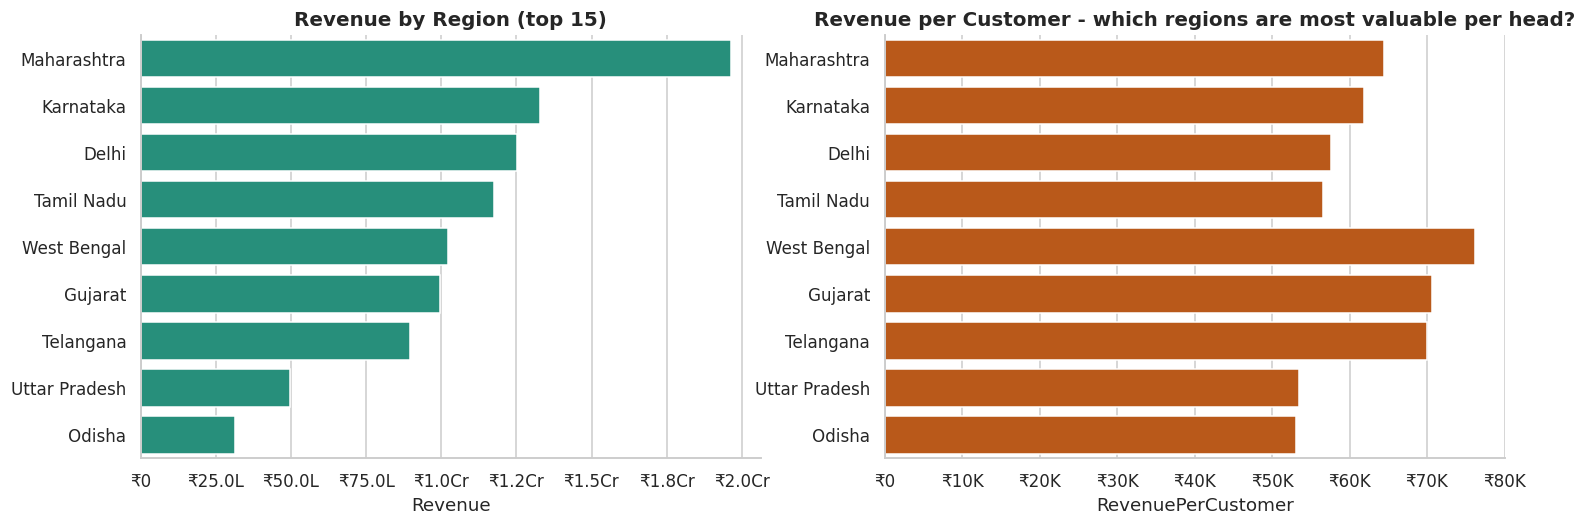

Best region: Maharashtra (20.8%)   Weakest: Odisha (3.3%)


In [11]:
reg = (clean.groupby("Region").agg(Revenue=("Revenue", "sum"), Customers=("CustomerID", "nunique"),
                                   Orders=("InvoiceNo", "nunique"))
            .sort_values("Revenue", ascending=False))
reg["Share"] = reg["Revenue"] / reg["Revenue"].sum()
reg["RevenuePerCustomer"] = reg["Revenue"] / reg["Customers"]
view = reg.head(15)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=view["Revenue"], y=view.index, ax=ax[0], color="#16a085"); inr_axis(ax[0], "x")
ax[0].set_title("Revenue by Region (top 15)"); ax[0].set_ylabel("")
sns.barplot(x=view["RevenuePerCustomer"], y=view.index, ax=ax[1], color="#d35400"); inr_axis(ax[1], "x")
ax[1].set_title("Revenue per Customer - which regions are most valuable per head?"); ax[1].set_ylabel("")
plt.show()
print(f"Best region: {reg.index[0]} ({reg['Share'].iloc[0]:.1%})   Weakest: {reg.index[-1]} ({reg['Share'].iloc[-1]:.1%})")

### 5.7 Customer analysis & Pareto principle

,value
Total customers,"1,500"
Avg spend per customer,"₹62,973"
Median spend per customer,"₹34,214"
Avg orders per customer,14.33
Repeat-customer rate (2+ orders),92.9%


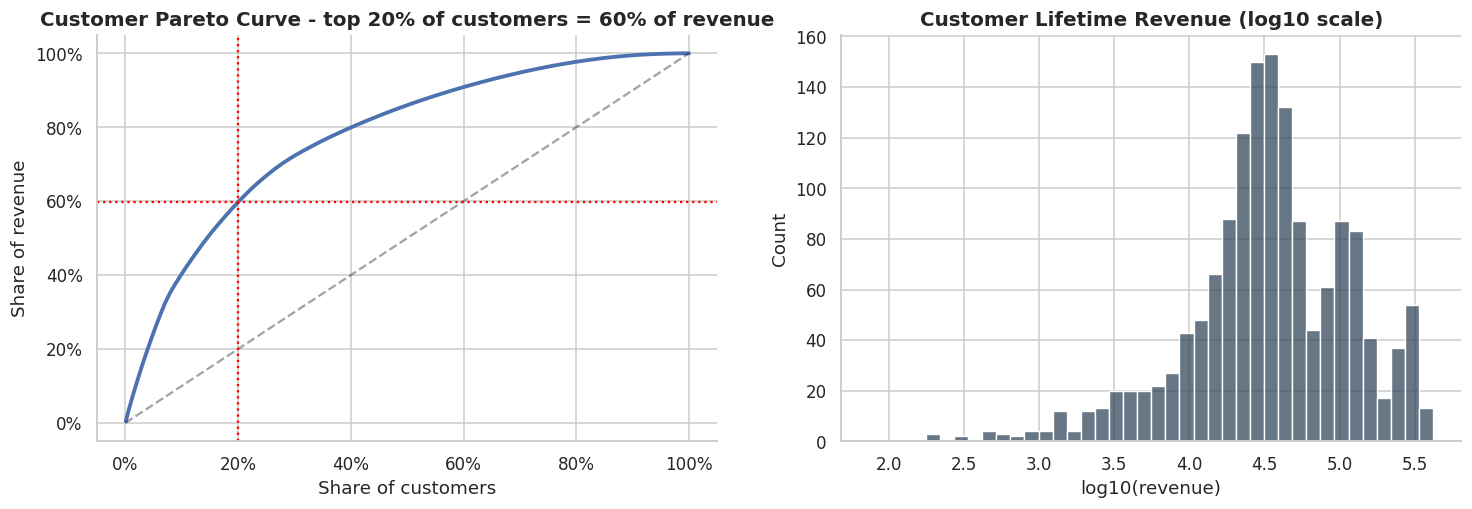

**Top 10 customers by revenue**

,CustomerID,Revenue,Orders,AOV
448,10449,418462.0,56,7473.0
1356,11357,389232.0,62,6278.0
1052,11053,386033.0,64,6032.0
1478,11479,385264.0,60,6421.0
549,10550,384488.0,59,6517.0
561,10562,365180.0,53,6890.0
363,10364,359208.0,58,6193.0
1259,11260,351278.0,63,5576.0
1364,11365,349439.0,67,5216.0
690,10691,345212.0,59,5851.0


**Top 10 customers by purchase frequency**

,CustomerID,Orders,Revenue,AOV
679,10680,71,327885.0,4618.0
612,10613,69,334087.0,4842.0
1186,11187,68,317634.0,4671.0
1364,11365,67,349439.0,5216.0
133,10134,66,308749.0,4678.0
489,10490,65,308943.0,4753.0
1096,11097,65,324524.0,4993.0
1052,11053,64,386033.0,6032.0
250,10251,63,301343.0,4783.0
1259,11260,63,351278.0,5576.0


In [12]:
cust = (clean.groupby("CustomerID")
             .agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique"), Units=("Quantity", "sum"),
                  FirstPurchase=("Date", "min"), LastPurchase=("Date", "max"))
             .assign(AOV=lambda d: d["Revenue"] / d["Orders"]))
display(pd.Series({
    "Total customers": f"{len(cust):,}",
    "Avg spend per customer": inr(cust["Revenue"].mean()),
    "Median spend per customer": inr(cust["Revenue"].median()),
    "Avg orders per customer": f"{cust['Orders'].mean():.2f}",
    "Repeat-customer rate (2+ orders)": f"{(cust['Orders'] > 1).mean():.1%}",
}, name="value").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
srt = cust["Revenue"].sort_values(ascending=False).reset_index(drop=True)
cum = srt.cumsum() / srt.sum(); pct = (np.arange(len(srt)) + 1) / len(srt)
ax[0].plot(pct, cum, lw=2.5); ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
top20 = cum.iloc[int(.2 * len(cum)) - 1]
ax[0].axvline(.2, color="red", ls=":"); ax[0].axhline(top20, color="red", ls=":")
ax[0].set_title(f"Customer Pareto Curve - top 20% of customers = {top20:.0%} of revenue")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set_xlabel("Share of customers"); ax[0].set_ylabel("Share of revenue")
sns.histplot(np.log10(cust["Revenue"]), bins=40, ax=ax[1], color="#34495e")
ax[1].set_title("Customer Lifetime Revenue (log10 scale)"); ax[1].set_xlabel("log10(revenue)")
plt.show()

c = cust.reset_index()
display(Markdown("**Top 10 customers by revenue**"))
display(c.nlargest(10, "Revenue")[["CustomerID", "Revenue", "Orders", "AOV"]].round(0))
display(Markdown("**Top 10 customers by purchase frequency**"))
display(c.nlargest(10, "Orders")[["CustomerID", "Orders", "Revenue", "AOV"]].round(0))

## 6. RFM Analysis

| Metric | Meaning | Calculation |
|---|---|---|
| **Recency** | days since last purchase (lower = better) | snapshot date − last purchase |
| **Frequency** | number of distinct orders | unique invoices |
| **Monetary** | total net spend | sum of revenue |

The snapshot date is one day after the last transaction in the data.

Snapshot date: 2026-01-01


,count,mean,std,min,25%,50%,75%,max
Recency,1500.0,124.1,164.8,1.0,12.0,35.0,209.2,715.0
Frequency,1500.0,14.3,14.4,1.0,5.8,9.0,20.0,71.0
Monetary,1500.0,62973.2,75312.3,74.5,18433.2,34214.1,78516.6,418461.5


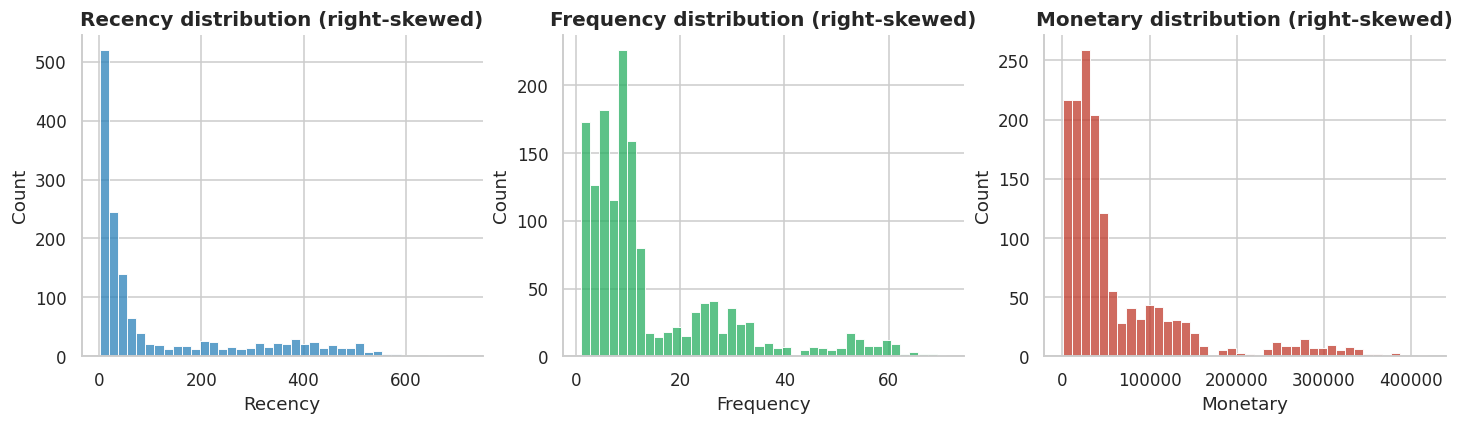

In [13]:
snapshot = clean["Date"].max() + pd.Timedelta(days=1)
rfm = clean.groupby("CustomerID").agg(
    Recency=("Date", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
print("Snapshot date:", snapshot.date())
display(rfm.describe().T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, col, colr in zip(ax, rfm.columns, ["#2980b9", "#27ae60", "#c0392b"]):
    sns.histplot(rfm[col], bins=40, ax=a_, color=colr); a_.set_title(f"{col} distribution (right-skewed)")
plt.show()

### 6.1 RFM scoring & named segments

Each metric is split into **quintiles (1–5, 5 = best)**. Ranks are used before binning so heavy ties (e.g. many one-time buyers) don't break `qcut`.
Segments follow the standard R/F-score grid.

,Customers,AvgRecency,AvgFrequency,AvgMonetary,Revenue,CustomerShare,RevenueShare
Segment,,,,,,,
Champions,366,9.63,31.97,150050.70,54918556.57,0.24,0.58
Loyal Customers,142,34.68,23.32,102048.83,14490934.15,0.09,0.15
At Risk Customers,273,215.53,10.59,41255.78,11262829.06,0.18,0.12
Lost Customers,327,338.35,4.85,18529.62,6059185.36,0.22,0.06
Need Attention,158,36.73,5.81,22473.31,3550782.54,0.11,0.04
Potential Loyalists,113,11.03,7.74,29679.88,3353826.67,0.08,0.04
New Customers,121,9.82,1.73,6806.88,823632.49,0.08,0.01


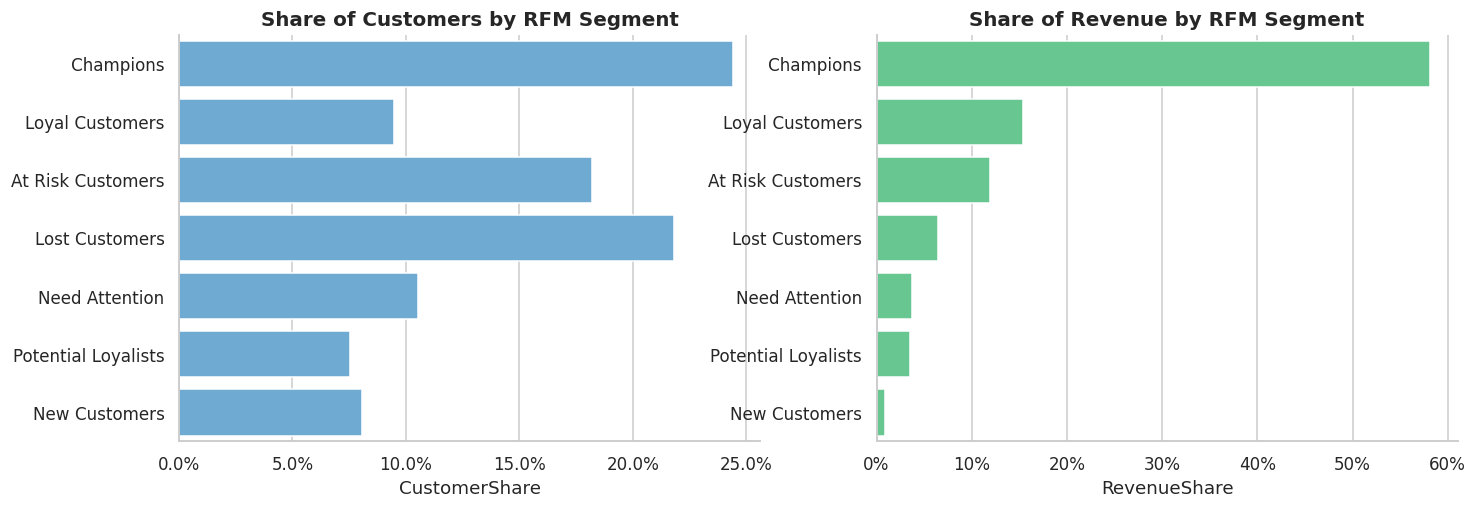

**Example - highest-value customer:** ID `10449` | Recency = 12 days | Frequency = 56 orders | Monetary = ₹4.18 L | Segment = Champions

In [14]:
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm[["R_Score", "F_Score", "M_Score"]].sum(axis=1)
rfm["RFM_Code"]  = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)

r, f = rfm["R_Score"], rfm["F_Score"]
rfm["Segment"] = np.select(
    [(r >= 4) & (f >= 4),            # recent + frequent
     (r >= 3) & (f >= 4),            # frequent, slightly cooling
     (r >= 4) & f.isin([2, 3]),      # recent, building habit
     (r >= 4) & (f == 1),            # recent, first purchases
     (r <= 2) & (f >= 3),            # used to buy often, gone quiet
     (r == 3) & (f <= 3),            # middle of the road
     (r <= 2) & (f <= 2)],           # inactive, low engagement
    ["Champions", "Loyal Customers", "Potential Loyalists", "New Customers",
     "At Risk Customers", "Need Attention", "Lost Customers"], default="Other")

seg = (rfm.groupby("Segment")
          .agg(Customers=("Recency", "size"), AvgRecency=("Recency", "mean"), AvgFrequency=("Frequency", "mean"),
               AvgMonetary=("Monetary", "mean"), Revenue=("Monetary", "sum"))
          .sort_values("Revenue", ascending=False))
seg["CustomerShare"] = seg["Customers"] / seg["Customers"].sum()
seg["RevenueShare"]  = seg["Revenue"] / seg["Revenue"].sum()
display(seg.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(x=seg["CustomerShare"], y=seg.index, ax=ax[0], color="#5dade2")
ax[0].set_title("Share of Customers by RFM Segment"); ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].set_ylabel("")
sns.barplot(x=seg["RevenueShare"], y=seg.index, ax=ax[1], color="#58d68d")
ax[1].set_title("Share of Revenue by RFM Segment"); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1].set_ylabel("")
plt.show()

top = rfm.sort_values("Monetary", ascending=False).iloc[0]
display(Markdown(f"**Example - highest-value customer:** ID `{top.name}` | Recency = {top.Recency:.0f} days | "
                 f"Frequency = {top.Frequency:.0f} orders | Monetary = {inr(top.Monetary)} | Segment = {top.Segment}"))

## 7. Customer Segmentation with K-Means

RFM variables are heavily right-skewed, which distorts distance-based clustering. Pipeline: **log1p transform → standardize → K-Means**.

The number of clusters is chosen using **both** the elbow curve (inertia) and the silhouette score.

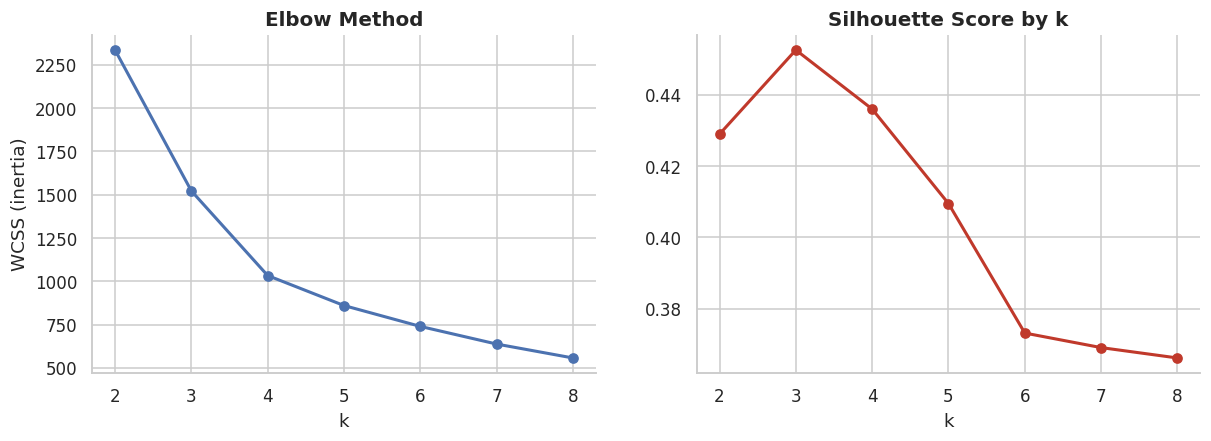

Selected k = 3  (silhouette = 0.453).  Override with K_OVERRIDE if business needs differ.


In [15]:
features = ["Recency", "Frequency", "Monetary"]
X_log = np.log1p(rfm[features])
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(X_log)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(rfm_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(rfm_scaled, km.labels_, sample_size=min(len(rfm_scaled), 5000), random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), inertia, "o-", lw=2); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("WCSS (inertia)")
ax[1].plot(list(ks), sil, "o-", lw=2, color="#c0392b"); ax[1].set_title("Silhouette Score by k"); ax[1].set_xlabel("k")
plt.show()

cands = {k: s for k, s in zip(ks, sil) if 3 <= k <= 6}
K = K_OVERRIDE or max(cands, key=cands.get)
print(f"Selected k = {K}  (silhouette = {dict(zip(ks, sil))[K]:.3f}).  Override with K_OVERRIDE if business needs differ.")

In [16]:
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

prof = (rfm.groupby("Cluster")
           .agg(Customers=("Recency", "size"), Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
                Monetary=("Monetary", "mean"), Revenue=("Monetary", "sum")))
prof["RevenueShare"] = prof["Revenue"] / prof["Revenue"].sum()

# data-driven names: recent vs. dormant  x  high vs. low value
rec_med, mon_med = rfm["Recency"].median(), rfm["Monetary"].median()
def name_cluster(row):
    recent, valuable = row["Recency"] <= rec_med, row["Monetary"] >= mon_med
    return {(True, True): "Active High-Value", (True, False): "Active Low-Value / New",
            (False, True): "At-Risk High-Value", (False, False): "Dormant Low-Value"}[(recent, valuable)]
names = prof.apply(name_cluster, axis=1)
dup = names.duplicated(keep=False)
prof["Label"] = [f"C{i}: {n}" if d else n for (i, n), d in zip(names.items(), dup)]
rfm["ClusterLabel"] = rfm["Cluster"].map(prof["Label"])
display(prof.round(2))

,Customers,Recency,Frequency,Monetary,Revenue,RevenueShare,Label
Cluster,,,,,,,
0,758,220.81,7.44,28549.07,21640191.79,0.23,C0: Dormant Low-Value
1,542,15.89,28.46,131785.62,71427807.83,0.76,Active High-Value
2,200,50.90,2.10,6958.74,1391747.22,0.01,C2: Dormant Low-Value


### 7.1 PCA visualization

Variance explained: PC1 = 70.7%, PC2 = 27.0%, total = 97.7%


,PC1,PC2
loadings,,
Recency,-0.383,0.922
Frequency,0.659,0.230
Monetary,0.647,0.312


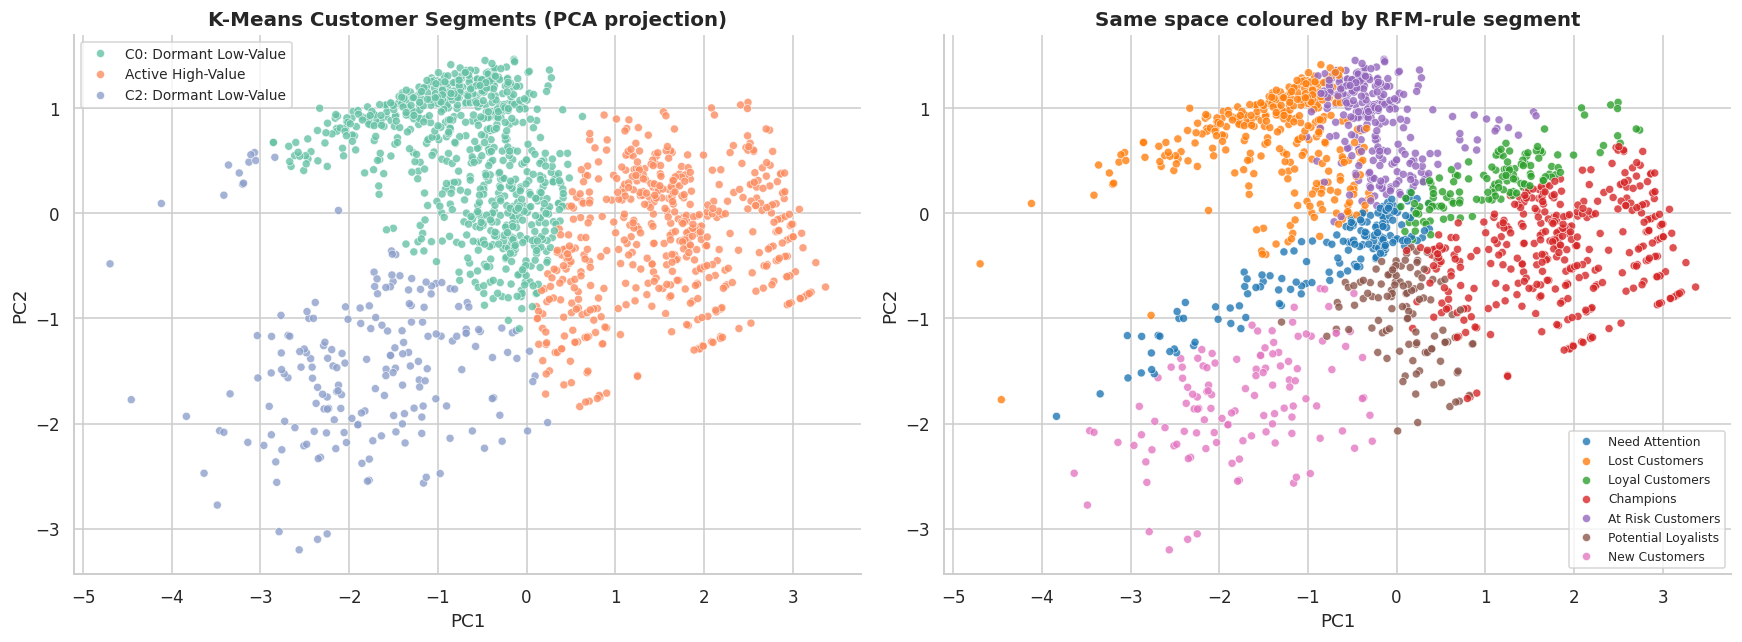

In [17]:
pca = PCA(n_components=2, random_state=SEED)
comp = pca.fit_transform(rfm_scaled)
rfm["PC1"], rfm["PC2"] = comp[:, 0], comp[:, 1]
print(f"Variance explained: PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}, "
      f"total = {pca.explained_variance_ratio_.sum():.1%}")
display(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(3).rename_axis("loadings"))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=rfm, x="PC1", y="PC2", hue="ClusterLabel", palette="Set2", s=28, alpha=.8, ax=ax[0])
ax[0].set_title("K-Means Customer Segments (PCA projection)"); ax[0].legend(title="", fontsize=9)
sns.scatterplot(data=rfm, x="PC1", y="PC2", hue="Segment", palette="tab10", s=28, alpha=.8, ax=ax[1])
ax[1].set_title("Same space coloured by RFM-rule segment"); ax[1].legend(title="", fontsize=8)
save_fig("customer_segments.png"); plt.show()

### 7.2 Cluster quality

,score
"Silhouette (higher better, max 1)",0.453
Davies-Bouldin (lower better),0.830
Calinski-Harabasz (higher better),1464.644


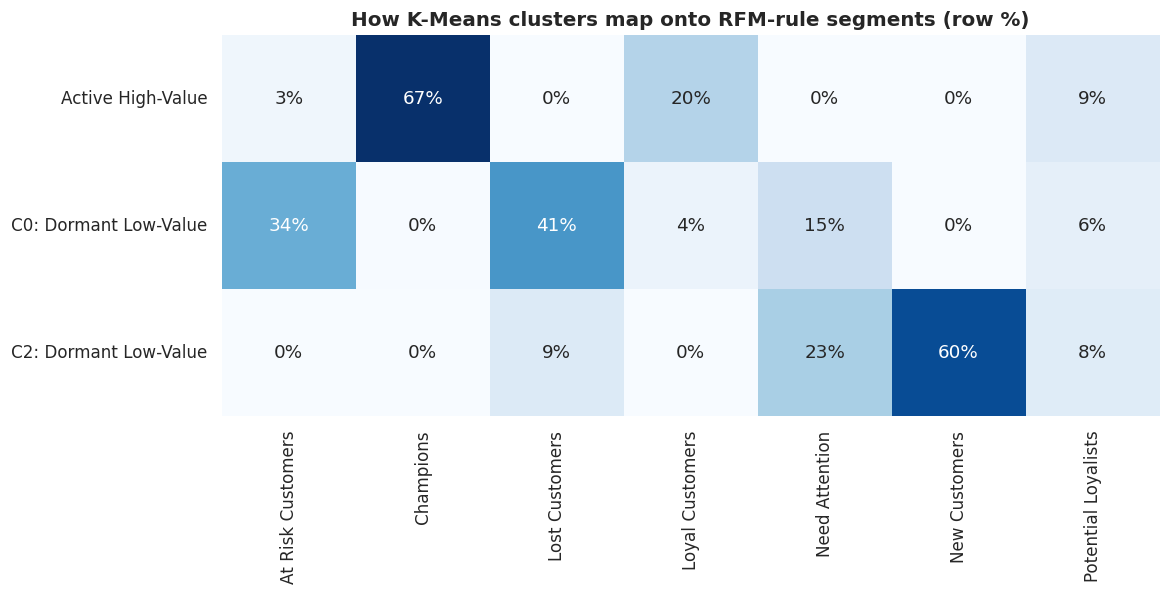

In [18]:
labels = rfm["Cluster"]
quality = pd.Series({
    "Silhouette (higher better, max 1)": silhouette_score(rfm_scaled, labels, sample_size=min(len(rfm_scaled), 10000), random_state=SEED),
    "Davies-Bouldin (lower better)": davies_bouldin_score(rfm_scaled, labels),
    "Calinski-Harabasz (higher better)": calinski_harabasz_score(rfm_scaled, labels),
}, name="score").round(3)
display(quality.to_frame())

ct = pd.crosstab(rfm["ClusterLabel"], rfm["Segment"], normalize="index")
plt.figure(figsize=(11, 3 + .5 * K))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("How K-Means clusters map onto RFM-rule segments (row %)"); plt.ylabel(""); plt.xlabel("")
plt.show()

## 8. Sales Prediction

### Design decision: forecast daily revenue, not single transactions

The brief suggests predicting `Revenue` from `Quantity`, `UnitPrice` and `Discount`. But `Revenue = Quantity × UnitPrice × (1 − Discount)` - a model given those columns just re-learns the formula and reports a near-perfect R² that means nothing (**target leakage**).

A business actually needs to know **how much will we sell tomorrow / next month?** So this notebook:
- aggregates to **daily revenue**,
- builds **calendar features** (weekday, month, weekend, festive season) and **history features** (lags, rolling means) that are known *before* the day happens,
- validates with a **time-based split** (train on the past, test on the future - never shuffle time series),
- compares against a **naive baseline** so improvements are honest.

Daily observations: 703  |  train: 562 (2024-01-29 -> 2025-08-12)  |  test: 141 (2025-08-13 -> 2025-12-31)


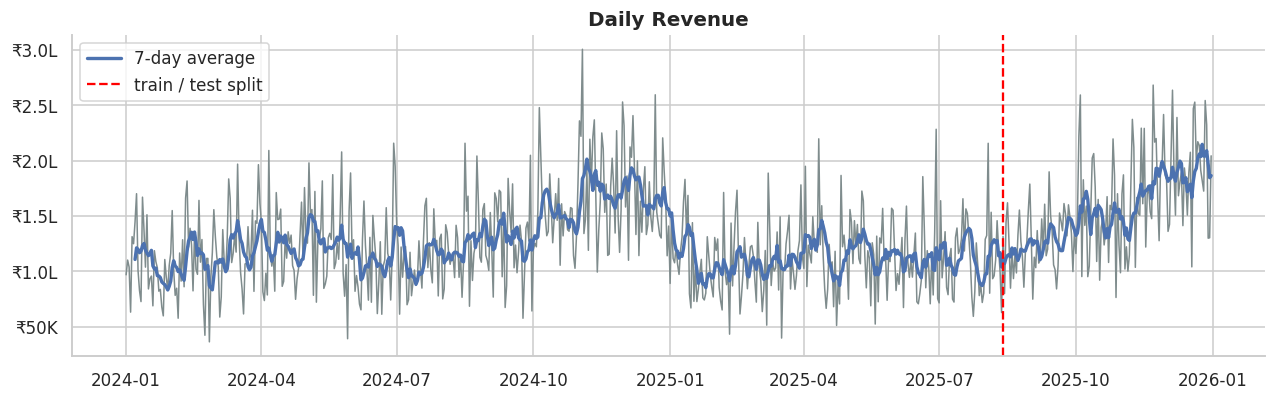

In [19]:
daily = clean.groupby("Date")["Revenue"].sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0.0)
daily.index.name = "Date"

def make_features(s):
    d = pd.DataFrame({"y": s})
    idx = d.index
    d["dow"] = idx.dayofweek
    d["month"] = idx.month
    d["day"] = idx.day
    d["weekofyear"] = idx.isocalendar().week.astype(int).values
    d["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    d["is_month_end"] = idx.is_month_end.astype(int)
    d["is_festive_q4"] = idx.month.isin([10, 11, 12]).astype(int)
    for l in (1, 7, 14, 28):
        d[f"lag_{l}"] = d["y"].shift(l)
    shifted = d["y"].shift(1)                      # shift first -> no leakage from the current day
    d["roll_mean_7"]  = shifted.rolling(7).mean()
    d["roll_mean_28"] = shifted.rolling(28).mean()
    d["roll_std_7"]   = shifted.rolling(7).std()
    return d

feat_df = make_features(daily).dropna()
FEATURES = [c for c in feat_df.columns if c != "y"]
X, y = feat_df[FEATURES], feat_df["y"]

split = int(len(X) * .8)
X_train, X_test, y_train, y_test = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
print(f"Daily observations: {len(X)}  |  train: {len(X_train)} ({X_train.index.min().date()} -> {X_train.index.max().date()})"
      f"  |  test: {len(X_test)} ({X_test.index.min().date()} -> {X_test.index.max().date()})")

plt.figure(figsize=(14, 3.8))
plt.plot(daily.index, daily.values, lw=1, color="#7f8c8d")
plt.plot(daily.rolling(7).mean(), lw=2.2, label="7-day average")
plt.axvline(X_test.index.min(), color="red", ls="--", label="train / test split")
plt.title("Daily Revenue"); inr_axis(plt.gca()); plt.legend(); plt.show()

### 8.1 Model comparison

In [20]:
def metrics(y_true, y_pred):
    nz = y_true > 0
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred),
            "MAPE %": float(np.mean(np.abs((y_true[nz] - y_pred[nz]) / y_true[nz])) * 100)}

models = {
    "Naive (same weekday last week)": None,
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest (baseline)": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(n_estimators=400, learning_rate=.05, max_depth=4, subsample=.8,
                                     colsample_bytree=.8, random_state=SEED, n_jobs=-1)
except ImportError:
    print("xgboost not installed - skipping (optional: pip install xgboost)")

results, preds = {}, {}
for name, m in models.items():
    if m is None:
        p = X_test["lag_7"].values
    else:
        m.fit(X_train, y_train); p = m.predict(X_test)
    preds[name] = p; results[name] = metrics(y_test.values, p)

fitted = {k: v for k, v in models.items() if v is not None}
comparison = pd.DataFrame(results).T.sort_values("MAE")
display(comparison.round(3).style.background_gradient(subset=["MAE", "RMSE", "MAPE %"], cmap="Greens_r")
                                  .background_gradient(subset=["R2"], cmap="Greens"))

,MAE,RMSE,R2,MAPE %
Ridge Regression,28555.616000,36386.579000,0.345000,19.542000
Random Forest (baseline),30075.187000,37327.219000,0.310000,20.996000
XGBoost,31865.863000,40456.478000,0.190000,21.812000
Hist Gradient Boosting,33034.817000,41593.752000,0.144000,22.224000
Naive (same weekday last week),40552.074000,49822.797000,-0.229000,27.667000


### 8.2 Hyper-parameter tuning (time-series cross-validation)

In [21]:
param_dist = {"n_estimators": [200, 300, 500], "max_depth": [6, 10, 16, None],
              "min_samples_leaf": [1, 2, 4, 8], "max_features": [.5, .7, 1.0]}
search = RandomizedSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1), param_dist, n_iter=15,
                            cv=TimeSeriesSplit(n_splits=5), scoring="neg_mean_absolute_error",
                            random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
tuned = search.best_estimator_
print("Best parameters:", search.best_params_)
print(f"CV MAE: {-search.best_score_:,.0f}")

fitted["Random Forest (tuned)"] = tuned
preds["Random Forest (tuned)"] = tuned.predict(X_test)
results["Random Forest (tuned)"] = metrics(y_test.values, preds["Random Forest (tuned)"])
comparison = pd.DataFrame(results).T.sort_values("MAE")
display(comparison.round(3))

best_name = comparison.index[0]
if best_name.startswith("Naive"):
    print("Warning: naive baseline wins - the signal may be too weak for ML on this dataset.")
display(Markdown(f"**Best model on the held-out future period: {best_name}**"))

Best parameters: {'n_estimators': 300, 'min_samples_leaf': 8, 'max_features': 0.7, 'max_depth': 16}
CV MAE: 27,645


,MAE,RMSE,R2,MAPE %
Ridge Regression,28555.616,36386.579,0.345,19.542
Random Forest (tuned),29138.682,36167.964,0.352,19.882
Random Forest (baseline),30075.187,37327.219,0.310,20.996
XGBoost,31865.863,40456.478,0.190,21.812
Hist Gradient Boosting,33034.817,41593.752,0.144,22.224
Naive (same weekday last week),40552.074,49822.797,-0.229,27.667


**Best model on the held-out future period: Ridge Regression**

### 8.3 Final evaluation

,Score
Metric,
MAE,"₹28,556"
RMSE,"₹36,387"
R²,0.345
MAPE,19.5%


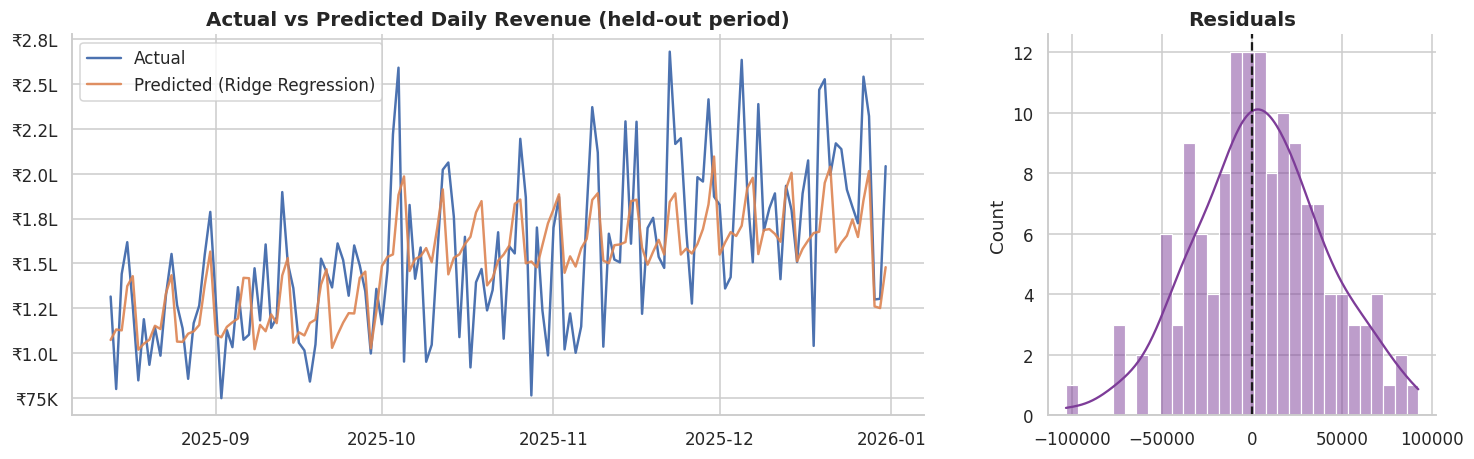

In [22]:
best_pred = preds[best_name]
final = metrics(y_test.values, best_pred)
display(pd.DataFrame({"Metric": ["MAE", "RMSE", "R²", "MAPE"],
                      "Score": [inr(final["MAE"]), inr(final["RMSE"]), f"{final['R2']:.3f}", f"{final['MAPE %']:.1f}%"]})
        .set_index("Metric"))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(y_test.index, y_test, label="Actual", lw=1.6)
ax[0].plot(y_test.index, best_pred, label=f"Predicted ({best_name})", lw=1.6, alpha=.9)
ax[0].set_title("Actual vs Predicted Daily Revenue (held-out period)"); ax[0].legend(); inr_axis(ax[0])
resid = y_test.values - best_pred
sns.histplot(resid, bins=30, kde=True, ax=ax[1], color="#7d3c98")
ax[1].set_title("Residuals"); ax[1].axvline(0, color="k", ls="--")
plt.show()

### 8.4 Feature importance — what drives sales?

Shown for the tuned Random Forest (tree models expose importances directly; permutation importance is computed on unseen test data so it is not biased toward noisy features).

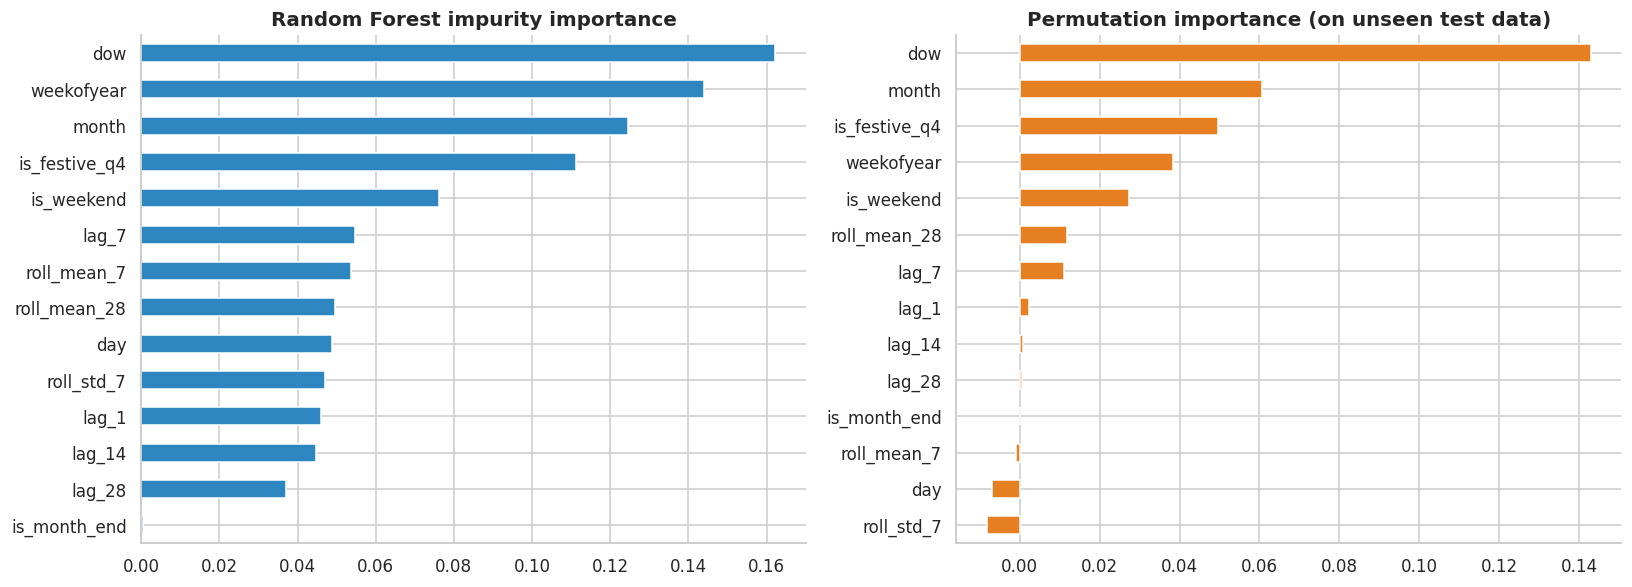

Top drivers (permutation): dow, month, is_festive_q4


In [23]:
imp_model = tuned
impurity = pd.Series(imp_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
perm = permutation_importance(imp_model, X_test, y_test, n_repeats=15, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
impurity.sort_values().plot.barh(ax=ax[0], color="#2e86c1"); ax[0].set_title("Random Forest impurity importance")
perm_s.sort_values().plot.barh(ax=ax[1], color="#e67e22"); ax[1].set_title("Permutation importance (on unseen test data)")
save_fig("feature_importance.png"); plt.show()
print("Top drivers (permutation):", ", ".join(perm_s.head(3).index))

### 8.5 Forecast the next 30 days

Forecasting with: Ridge Regression


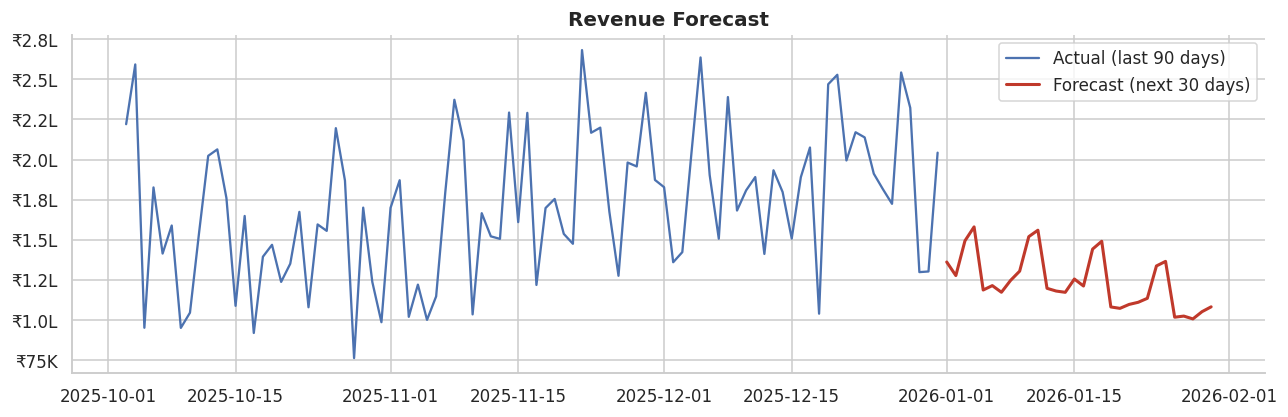

Forecast revenue for the next 30 days: ₹37.26 L
Last 30 days: ₹56.55 L  (seasonal context matters - compare with the same period last year below)
Same 30 days one year earlier: ₹32.50 L
Recursive forecasts get less reliable further out - treat the tail as indicative, not exact.


In [24]:
from sklearn.base import clone
# refit the best model on ALL history, then forecast recursively (each prediction feeds the next day's lag features)
forecast_name = best_name if best_name in fitted else "Random Forest (tuned)"
final_model = clone(fitted[forecast_name]).fit(X, y)
print("Forecasting with:", forecast_name)

hist = daily.copy()
for _ in range(FORECAST_DAYS):
    nxt = hist.index[-1] + pd.Timedelta(days=1)
    tmp = pd.concat([hist, pd.Series([np.nan], index=[nxt])])
    row = make_features(tmp).iloc[[-1]][FEATURES]
    hist = pd.concat([hist, pd.Series([final_model.predict(row)[0]], index=[nxt])])

fc = hist.iloc[-FORECAST_DAYS:]
plt.figure(figsize=(14, 4))
recent = daily.iloc[-90:]
plt.plot(recent.index, recent.values, label="Actual (last 90 days)")
plt.plot(fc.index, fc.values, color="#c0392b", lw=2, label=f"Forecast (next {FORECAST_DAYS} days)")
plt.title("Revenue Forecast"); inr_axis(plt.gca()); plt.legend(); plt.show()
print(f"Forecast revenue for the next {FORECAST_DAYS} days: {inr(fc.sum())}")
print(f"Last {FORECAST_DAYS} days: {inr(daily.iloc[-FORECAST_DAYS:].sum())}  (seasonal context matters - compare with the same period last year below)")
ly = daily.reindex(fc.index - pd.Timedelta(days=365))
if ly.notna().all(): print(f"Same {FORECAST_DAYS} days one year earlier: {inr(ly.sum())}")
print("Recursive forecasts get less reliable further out - treat the tail as indicative, not exact.")

### 8.6 Revenue contribution by customer segment

This view complements the cluster visualization by showing how much revenue each behavioural segment contributes. It helps translate segmentation into retention and marketing priorities.

In [ ]:
segment_revenue = seg.sort_values("Revenue", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
segment_revenue["Revenue"].plot.barh(ax=ax)
ax.set_title("Revenue Contribution by Customer Segment")
ax.set_xlabel("Revenue")
inr_axis(ax)
for i, v in enumerate(segment_revenue["Revenue"]):
    ax.text(v, i, f"  {v/clean['Revenue'].sum():.1%}", va="center")
save_fig("segment_revenue_contribution.png")
plt.show()

## 9. Business Insights (auto-generated from the results above)

In [25]:
champ = seg.loc["Champions"] if "Champions" in seg.index else None
risk  = seg.loc["At Risk Customers"] if "At Risk Customers" in seg.index else None
lost  = seg.loc["Lost Customers"] if "Lost Customers" in seg.index else None
best_cluster = prof["Revenue"].idxmax()
peak_months = seasonal.nlargest(3).index.tolist()
month_name = lambda m: pd.Timestamp(2000, m, 1).strftime("%b")
disc_corr = clean.groupby("Month").agg(d=("Discount", "mean"), r=("Revenue", "sum")).corr().iloc[0, 1]

lines = [f"### Key findings",
 f"- **Concentration:** the top 20% of customers generate **{top20:.0%}** of revenue; {n80} of {len(prod)} products produce 80% of sales.",
 f"- **Category / region:** **{cat.index[0]}** leads categories ({cat['Share'].iloc[0]:.0%} of revenue); **{reg.index[0]}** leads regions ({reg['Share'].iloc[0]:.0%}).",
 f"- **Seasonality:** strongest months are **{', '.join(month_name(m) for m in peak_months)}**; best weekday is **{dow['Revenue'].idxmax()}**.",
 f"- **Retention:** repeat-customer rate is **{(cust['Orders'] > 1).mean():.0%}**."]
if champ is not None:
    lines.append(f"- **Champions:** {champ['CustomerShare']:.0%} of customers drive **{champ['RevenueShare']:.0%}** of revenue.")
if risk is not None:
    lines.append(f"- **Revenue at risk:** {int(risk['Customers']):,} 'At Risk' customers (avg {risk['AvgRecency']:.0f} days inactive) "
                 f"previously spent **{inr(risk['Revenue'])}** ({risk['RevenueShare']:.0%} of revenue).")
lines += [f"- **Forecast:** best model (**{best_name}**) reaches MAPE {final['MAPE %']:.1f}% and R² {final['R2']:.2f} on unseen future days.",
 "", "### Recommended actions",
 "1. **Win-back campaign** for At-Risk / At-Risk High-Value customers - personalised offers sized to their past spend, sent before they become 'Lost'.",
 "2. **VIP / loyalty programme** for Champions and Loyal customers (early access, free shipping, referral rewards) - protect the revenue base.",
 "3. **Onboarding journey** for New Customers (second-purchase incentive) - converting them to repeat buyers is the cheapest growth lever.",
 f"4. **Inventory & staffing:** stock up for {', '.join(month_name(m) for m in peak_months)} and for {dow['Revenue'].idxmax()}s; prioritise availability of the top-revenue products.",
 f"5. **Regional playbook:** replicate what works in {reg.index[0]} in the weakest regions; check revenue-per-customer to separate reach problems from value problems.",
 "6. **Discounts:** test targeted rather than blanket discounts - compare uplift per segment before the next festive season."]
display(Markdown("\n".join(lines)))

### Key findings
- **Concentration:** the top 20% of customers generate **60%** of revenue; 30 of 60 products produce 80% of sales.
- **Category / region:** **Electronics** leads categories (36% of revenue); **Maharashtra** leads regions (21%).
- **Seasonality:** strongest months are **Dec, Nov, Oct**; best weekday is **Saturday**.
- **Retention:** repeat-customer rate is **93%**.
- **Champions:** 24% of customers drive **58%** of revenue.
- **Revenue at risk:** 273 'At Risk' customers (avg 216 days inactive) previously spent **₹1.13 Cr** (12% of revenue).
- **Forecast:** best model (**Ridge Regression**) reaches MAPE 19.5% and R² 0.34 on unseen future days.

### Recommended actions
1. **Win-back campaign** for At-Risk / At-Risk High-Value customers - personalised offers sized to their past spend, sent before they become 'Lost'.
2. **VIP / loyalty programme** for Champions and Loyal customers (early access, free shipping, referral rewards) - protect the revenue base.
3. **Onboarding journey** for New Customers (second-purchase incentive) - converting them to repeat buyers is the cheapest growth lever.
4. **Inventory & staffing:** stock up for Dec, Nov, Oct and for Saturdays; prioritise availability of the top-revenue products.
5. **Regional playbook:** replicate what works in Maharashtra in the weakest regions; check revenue-per-customer to separate reach problems from value problems.
6. **Discounts:** test targeted rather than blanket discounts - compare uplift per segment before the next festive season.

## 10. Final Dashboard-Style Summary

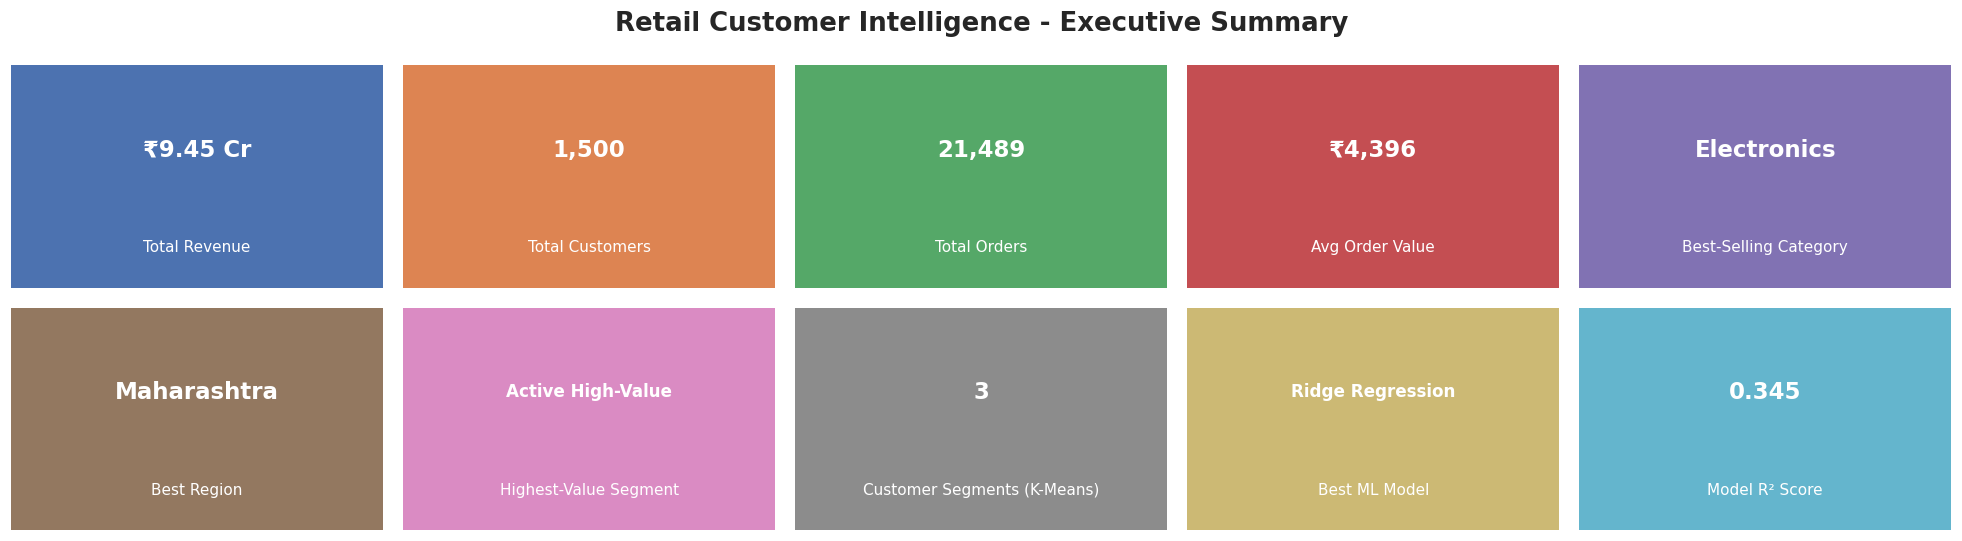

,value
Total Revenue,₹9.45 Cr
Total Customers,"1,500"
Total Orders,"21,489"
Avg Order Value,"₹4,396"
Best-Selling Category,Electronics
Best Region,Maharashtra
Highest-Value Segment,Active High-Value
Customer Segments (K-Means),3
Best ML Model,Ridge Regression
Model R² Score,0.345


In [26]:
summary = {
    "Total Revenue": inr(clean["Revenue"].sum()),
    "Total Customers": f"{clean['CustomerID'].nunique():,}",
    "Total Orders": f"{clean['InvoiceNo'].nunique():,}",
    "Avg Order Value": inr(order_values.mean()),
    "Best-Selling Category": cat.index[0],
    "Best Region": reg.index[0],
    "Highest-Value Segment": f"{prof.loc[best_cluster, 'Label']}",
    "Customer Segments (K-Means)": str(K),
    "Best ML Model": best_name,
    "Model R² Score": f"{final['R2']:.3f}",
}
fig, axes = plt.subplots(2, 5, figsize=(18, 5))
palette = sns.color_palette("deep", 10)
for ax_, (k_, v_), c_ in zip(axes.ravel(), summary.items(), palette):
    ax_.set_facecolor(c_); ax_.set_xticks([]); ax_.set_yticks([])
    for s in ax_.spines.values(): s.set_visible(False)
    ax_.text(.5, .62, v_, ha="center", va="center", fontsize=15 if len(str(v_)) < 16 else 11,
             color="white", fontweight="bold", wrap=True)
    ax_.text(.5, .18, k_, ha="center", va="center", fontsize=10, color="white")
fig.suptitle("Retail Customer Intelligence - Executive Summary", fontsize=17, fontweight="bold")
save_fig("dashboard_summary.png"); plt.show()
display(pd.Series(summary, name="value").to_frame())

## 11. Export Results

In [27]:
rfm.reset_index().to_csv(OUT_DIR / "customer_segments.csv", index=False)
comparison.round(4).to_csv(OUT_DIR / "model_comparison.csv")
fc.rename("forecast_revenue").to_csv(OUT_DIR / "forecast_next_days.csv")
seg.round(4).to_csv(OUT_DIR / "rfm_segment_summary.csv")
print("Saved ->", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))
print("Images ->", ", ".join(sorted(p.name for p in IMG_DIR.iterdir())))

Saved -> customer_segments.csv, forecast_next_days.csv, model_comparison.csv, rfm_segment_summary.csv
Images -> category_analysis.png, customer_segments.png, dashboard_summary.png, feature_importance.png, sales_trend.png


## 12. Conclusion & Limitations

**What was built:** a full analytics pipeline that goes from raw transactions to segments, a validated forecasting model, and concrete actions.

**Limitations / next steps**
- Segments are behavioural snapshots - re-run periodically; add churn *prediction* (label customers inactive for N days and classify).
- The forecast uses only history + calendar. Adding promotions, holidays (Diwali date shifts every year), marketing spend and pricing would improve accuracy.
- Product-level or region-level forecasts (hierarchical) would help inventory planning.
- With real data, check for partial first/last months, B2B bulk orders (outliers), and returns (dropped here).